# 13. Many switches, few variables: motor price lists

Notebook 09 showed that a `jnp.where` in Python is a disjunction in an algebraic model. There the equation-based solvers were still
much faster, because the models had only a handful of switches. This notebook looks for the case where representing a switch
natively pays off: **few continuous variables and many switches.** It also shows a closely related model where it does not, and a
kind of switching model where jaxglobal is the one that fails.

The argument is about how each approach scales:

* **jaxglobal** branches on the continuous variables only. Once a box is small enough, interval arithmetic decides which side of a
  `where` applies on the whole box, so a switch adds work to each bound evaluation but no new dimension to the search.
* **An equation-based model** needs a binary variable per switch, plus constraints that tie it to the continuous variables. The
  search then runs over the binaries too, unless presolve can fix them.

Which of the two wins depends less on the number of switches than on whether the solver can tell, cheaply, which switches matter.
The three models below are chosen so that each answer to that question shows up once.

The models are pipe networks whose pump motors are bought from a price list. In code, a price list is one line.

Solver limits for the live comparison: relative gap 1e-4, at most 300 s (not the 60 s of the other notebooks: jaxglobal needed
about 75 s in the benchmark runs, most of it compiling on the first call). The scaling runs use 600 s and are read from
`benchmarks/results/many_switches.csv` (the command that regenerates it is given below).

In [1]:
import os

os.environ.setdefault("RUST_LOG", "warn")  # keep the local NLP solver's info messages out of the output

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyomo.environ as pyo

from nbutil import loc, model_size, save_results, solve_jax, solve_pyomo, table

from jaxglobal.applications import logic  # importing jaxglobal enables float64, before any JAX computation

INK, MUTED, BLUE, ORANGE = "#1a1a19", "#77766f", "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6, "figure.dpi": 110})  # fmt: skip

## The model: two parallel lines, each with its own pump

Water (0.3 m3/s in total) is delivered through two parallel steel lines, 2000 m and 3000 m long. Each line has its own pump. The
decision variables are the fraction $s$ of the flow sent through the first line and the two diameters:

* $s \in [0.1, 0.9]$: each line must carry at least 10% of the flow, so that either can be taken out of service gradually.
* $D_1, D_2 \in [0.15, 0.6]$ m.

Head loss uses Darcy-Weisbach with the Swamee-Jain friction factor [swamee1976explicit]; the flow is turbulent everywhere on this
box. With total flow $Q = 0.3$ m3/s, line flows $q_1 = sQ$ and $q_2 = (1-s)Q$, the pump power of line $i$ is

$$ v_i = \frac{4 q_i}{\pi D_i^2},\qquad \mathrm{Re}_i = \frac{\rho v_i D_i}{\mu},\qquad
   f_i = \frac{0.25}{\left[\log_{10}\!\left(\dfrac{\varepsilon}{3.7 D_i} + \dfrac{5.74}{\mathrm{Re}_i^{0.9}}\right)\right]^2},\qquad
   W_i = f_i\,\frac{L_i}{D_i}\,\frac{\rho v_i^2}{2}\,\frac{q_i}{\eta}, $$

with $\rho = 1000$ kg/m3, $\mu = 10^{-3}$ Pa s, roughness $\varepsilon = 4.5\cdot 10^{-5}$ m and pump efficiency $\eta = 0.7$.

Cost per year is energy ($e = 0.8$ \$/yr per W), pipe ($100\,L D^{1.5}$), and **the two motors**. Motors come in standard
ratings $P_1 < \dots < P_K$, and for each line you pay for the smallest rating that covers its pump power. The ratings are the
$K = 26$ IEC 60034 values from 0.37 to 315 kW. The price $c_k = 900\,P_k^{0.75} + 300$ \$/yr ($P_k$ in kW) is illustrative.
The price of the smallest covering motor is a staircase: the base price plus a step $\Delta c_k = c_{k+1} - c_k$ for every
rating the load exceeds. With $[\cdot]$ equal to 1 when its argument is true and 0 otherwise,

$$ \min_{s,\,D_1,\,D_2}\ \sum_{i=1}^{2}\Big( c_1 + \sum_{k=1}^{K-1} \Delta c_k\,[W_i > P_k] + e\,W_i + 100\,L_i D_i^{1.5} \Big)
   \quad\text{s.t.}\quad W_i \le P_K,\ i = 1, 2. $$

A slightly larger pipe can let a line use the next smaller motor, so the optimum tends to sit exactly on a rating boundary.

### jaxglobal

A motor's price is the base price plus the step up at every rating its load exceeds: one `jnp.where` over the rating table.

In [2]:
RHO, MU, EPS = 1000.0, 1e-3, 4.5e-5  # water; commercial steel roughness, m
QT, L = 0.3, np.array([2000.0, 3000.0])  # m3/s; m
ETA, E_COST, C_PIPE = 0.7, 0.8, 100.0
KW = np.array([0.37, 0.55, 0.75, 1.1, 1.5, 2.2, 3, 4, 5.5, 7.5, 11, 15, 18.5, 22, 30, 37, 45, 55, 75, 90, 110,
               132, 160, 200, 250, 315])  # IEC 60034 motor ratings, kW  # fmt: skip
PRICE = 900.0 * KW**0.75 + 300.0  # $/yr, illustrative
LO, HI = np.array([0.1, 0.15, 0.15]), np.array([0.9, 0.6, 0.6])


def power(x):  # W, for each line
    q = QT * jnp.array([x[0], 1 - x[0]])
    D = x[1:]
    v = 4 * q / (jnp.pi * D**2)
    Re = RHO * v * D / MU
    f = 0.25 / jnp.log10(EPS / (3.7 * D) + 5.74 / Re**0.9) ** 2
    return f * L / D * RHO * v**2 / 2 * q / ETA


def cost(x):
    W = power(x)
    motors = PRICE[0] + jnp.sum(jnp.where(W[:, None] / 1000 > KW[:-1], np.diff(PRICE), 0.0), axis=1)  # smallest motor covering W
    return jnp.sum(motors + E_COST * W) + C_PIPE * jnp.sum(L * x[1:] ** 1.5)


def big_enough(x):  # g(x) <= 0: the largest motor covers each load
    return power(x) / 1000 - KW[-1]

### Pyomo

The natural formulation buys exactly one rating per line, with binaries $y_{ik}$:

$$ \min\ \sum_{i=1}^{2}\Big(\sum_{k=1}^{K} c_k\,y_{ik} + e\,W_i + 100\,L_i D_i^{1.5}\Big)\quad\text{s.t.}\quad
   \sum_{k=1}^{K} y_{ik} = 1,\qquad W_i \le \sum_{k=1}^{K} P_k\,y_{ik},\qquad y_{ik}\in\{0,1\}, $$

with $W_i$ the same expression as above. Because the prices increase with the rating, the solver never buys a larger motor than
it needs, so this is exact. It is tighter than a big-M translation of the `where` steps (that version is what `jaxglobal.export`
would produce), so it is the fair comparison. The model has $2K$ binaries next to its three continuous variables.

In [3]:
def lines_pyomo():
    m = pyo.ConcreteModel()
    m.x = pyo.Var(range(3), bounds=lambda m, i: (LO[i], HI[i]), initialize=[0.6, 0.4, 0.3])
    m.y = pyo.Var(range(2), range(len(KW)), domain=pyo.Binary)
    m.c = pyo.ConstraintList()
    W = []
    for i in range(2):
        q = QT * (m.x[0] if i == 0 else 1 - m.x[0])
        D = m.x[1 + i]
        v = 4 * q / (np.pi * D**2)
        Re = RHO * v * D / MU
        f = 0.25 / pyo.log10(EPS / (3.7 * D) + 5.74 / Re**0.9) ** 2
        W.append(f * L[i] / D * RHO * v**2 / 2 * q / ETA)
        m.c.add(sum(m.y[i, k] for k in range(len(KW))) == 1)
        m.c.add(W[i] / 1000 <= sum(KW[k] * m.y[i, k] for k in range(len(KW))))
    m.obj = pyo.Objective(expr=sum(PRICE[k] * m.y[i, k] for i in range(2) for k in range(len(KW))) + E_COST * sum(W)
                          + C_PIPE * sum(L[i] * m.x[1 + i] ** 1.5 for i in range(2)))  # fmt: skip
    return m

The same model, for every price-list length used below, is `motor_lines_<K>` in `jaxglobal/applications/logic.py`. That copy is
what the flagship benchmark runs. Check that it is the model written here:

In [4]:
f26, g26 = logic.motor_lines(26)
X = jnp.asarray(np.random.default_rng(0).uniform(LO, HI, (2000, 3)))
assert np.allclose(jax.vmap(cost)(X), jax.vmap(f26)(X), rtol=1e-12)
assert np.allclose(jax.vmap(big_enough)(X), jax.vmap(g26)(X), rtol=1e-12)

## The 26-rating price list

In [5]:
m = lines_pyomo()
size = model_size(m)
print(f"Pyomo: {size[0]} variables ({2 * len(KW)} binary), {size[1]} constraints")
TLIM = 300
rows = [solve_pyomo(lines_pyomo(), s, tlim=TLIM) for s in ("scip", "couenne", "baron")]
rows.append(solve_jax(cost, LO, HI, ineq=big_enough, tlim=TLIM))
table(rows)

Pyomo: 55 variables (52 binary), 4 constraints


,solver,obj,bound,time,status
0,scip,129893.957391,129879.197666,300.28,maxTimeLimit
1,couenne,129894.006082,NaN,244.52,optimal
2,baron,NaN,NaN,NaN,not run: GAMS/BARON not installed
3,jaxglobal,129895.857740,129883.207432,28.13,optimal


In [6]:
xj = rows[-1]["x"]
Wj = np.asarray(power(jnp.asarray(xj))) / 1000
print(f"jaxglobal: s = {xj[0]:.4f}, D = {np.round(xj[1:], 4)} m")
for i in range(2):
    Pi = KW[np.searchsorted(KW, Wj[i] - 1e-9)]
    print(f"  line {i + 1}: pump power {Wj[i]:.4f} kW, motor {Pi} kW ({100 * (1 - Wj[i] / Pi):.3f}% below the rating)")

jaxglobal: s = 0.9000, D = [0.5089 0.197 ] m
  line 1: pump power 18.4973 kW, motor 18.5 kW (0.015% below the rating)
  line 2: pump power 5.4987 kW, motor 5.5 kW (0.023% below the rating)


In [7]:
lp, lj = loc(lines_pyomo), loc(power, cost, big_enough)
save_results("13", "A: two lines, 26 motor ratings", lp, lj, size, rows, note=f"{2 * len(KW)} binaries, one per rating and line")
print(f"lines of model code: Pyomo {lp}, jaxglobal {lj}")

lines of model code: Pyomo 18, jaxglobal 13


The flow split sits at its bound: the shorter line carries 90%. Each pump runs just below a standard rating (the shortfall printed
above is a few hundredths of a percent, the size of the solver tolerance), so each motor is fully loaded. Which solver is faster
at 26 ratings depends on the SCIP build and the machine: in the benchmark file read below (SCIP 6.3 through `pyscipopt`), SCIP
proved the optimum in 26 s against jaxglobal's 76 s; compare the live table above, which uses whatever `scip` binary is installed.

## Where the optimum sits, and what each solver sees

The staircase below is the motor price as a function of pump power. The dashed line is what the binary formulation looks like to
an LP relaxation: with $y_{ik}$ allowed to be fractional, the cheapest way to satisfy $\sum_k y_{ik} = 1$ and
$W_i \le \sum_k P_k y_{ik}$ is a mix of the smallest and the largest motor (the price curve is concave, so its convex hull is the
chord between the end points). That bound is far below the staircase in the range where the optimum lies, and the solver closes
the difference by branching on the binaries and adding cuts.

jaxglobal bounds the same staircase differently. On a box, interval arithmetic gives a range $[\underline W_i, \overline W_i]$ for
each pump power. Every rating outside that range has its `where` decided on the whole box, so the motor price on the box is at
least the staircase at $\underline W_i$. Once boxes are small, only those that straddle a rating boundary (the surface
$W_i(x) = P_k$) carry an undecided switch, and they are split like any other box. More ratings mean more boundary surfaces and
more boxes, but the search is still over $(s, D_1, D_2)$.

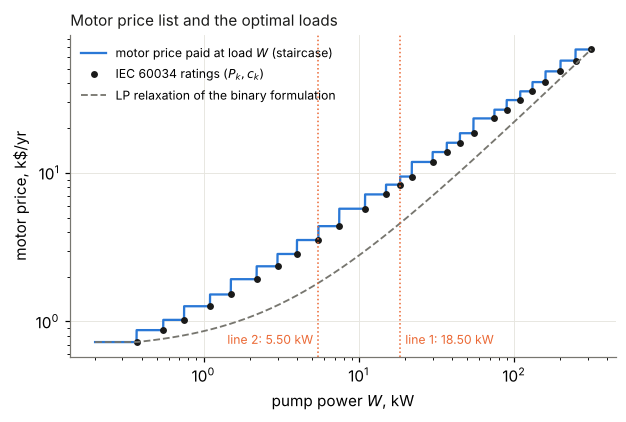

line 1 at 18.50 kW: staircase 8328 $/yr, LP relaxation 4579 $/yr
line 2 at 5.50 kW: staircase 3532 $/yr, LP relaxation 1817 $/yr


In [8]:
w = np.geomspace(0.2, KW[-1], 4000)  # kW
stair = PRICE[0] + np.sum(np.where(w[:, None] > KW[:-1], np.diff(PRICE), 0.0), axis=1)  # same expression as in cost()
chord = PRICE[0] + (PRICE[-1] - PRICE[0]) * np.clip((w - KW[0]) / (KW[-1] - KW[0]), 0, 1)  # LP relaxation of the y's
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(w, stair / 1000, color=BLUE, lw=1.5, label="motor price paid at load $W$ (staircase)")
ax.plot(KW, PRICE / 1000, "o", color=INK, ms=3.5, label="IEC 60034 ratings $(P_k, c_k)$")
ax.plot(w, chord / 1000, "--", color=MUTED, lw=1.2, label="LP relaxation of the binary formulation")
for i, wi in enumerate(Wj):
    ax.axvline(wi, color=ORANGE, lw=1, ls=":")
    ax.text(wi * (1.08 if i == 0 else 1 / 1.08), 0.04, f"line {i + 1}: {wi:.2f} kW", color=ORANGE, fontsize=8,
            ha="left" if i == 0 else "right", transform=ax.get_xaxis_transform())  # fmt: skip
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("pump power $W$, kW")
ax.set_ylabel("motor price, k\\$/yr")
ax.set_title("Motor price list and the optimal loads", loc="left", fontsize=10, color=INK)
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.show()
for i, wi in enumerate(Wj):
    st = PRICE[0] + np.sum(np.where(wi > KW[:-1], np.diff(PRICE), 0.0))
    ch = PRICE[0] + (PRICE[-1] - PRICE[0]) * (wi - KW[0]) / (KW[-1] - KW[0])
    print(f"line {i + 1} at {wi:.2f} kW: staircase {st:.0f} $/yr, LP relaxation {ch:.0f} $/yr")

To see the jumps in the cost itself, fix two of the variables at jaxglobal's optimum and vary one diameter. The pump power falls
as the pipe gets wider, so each time it drops below a rating the motor gets cheaper and the cost jumps down (dotted lines). The
dashed curve is the cost if motors could be bought in any size at the price $c(W) = 900\,W^{0.75} + 300$: the staircase is
never below it and touches it only at the ratings. The optimum sits just to the right of a jump, at the smallest diameter that
lets the line use the next smaller motor.

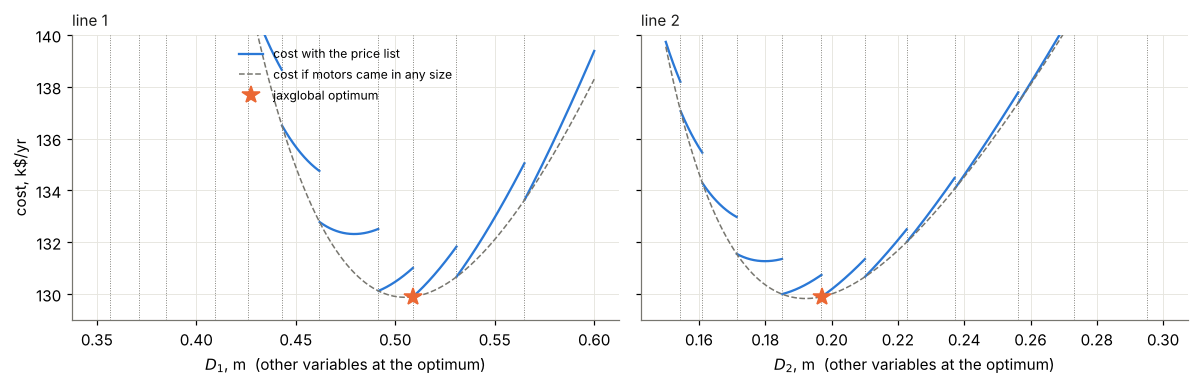

In [9]:
cost_v, power_v = jax.jit(jax.vmap(cost)), jax.jit(jax.vmap(power))
fj = float(cost(jnp.asarray(xj)))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, i, (a, b) in zip(axes, (1, 2), ((0.35, 0.6), (0.15, 0.3))):
    d = np.linspace(a, b, 3001)
    X = np.tile(xj, (d.size, 1))
    X[:, i] = d
    C = np.asarray(cost_v(jnp.asarray(X)))
    Wd = np.asarray(power_v(jnp.asarray(X))) / 1000  # kW, both lines
    jump = np.flatnonzero(np.diff(np.searchsorted(KW, Wd[:, i - 1] - 1e-12)))  # the line's motor changes here
    Cp = C.copy()
    Cp[jump + 1] = np.nan  # do not draw the vertical jumps
    any_size = np.sum(900 * Wd**0.75 + 300 + E_COST * 1000 * Wd, axis=1) + C_PIPE * np.sum(L * X[:, 1:] ** 1.5, axis=1)
    ax.plot(d, Cp / 1000, color=BLUE, lw=1.5, label="cost with the price list")
    ax.plot(d, any_size / 1000, "--", color=MUTED, lw=1, label="cost if motors came in any size")
    for j in jump:
        ax.axvline(d[j], color=MUTED, lw=0.6, ls=":")
    ax.plot(xj[i], fj / 1000, "*", color=ORANGE, ms=12, label="jaxglobal optimum")
    ax.set_xlabel(f"$D_{i}$, m  (other variables at the optimum)")
    ax.set_title(f"line {i}", loc="left", fontsize=10, color=INK)
axes[0].set_ylabel("cost, k\\$/yr")
axes[0].set_ylim(129, 140)
axes[0].legend(frameon=False, fontsize=8, loc="upper center")
fig.tight_layout()
plt.show()

At the optimal split, $W_1$ depends only on $D_1$ and $W_2$ only on $D_2$, so the rating boundaries in the $(D_1, D_2)$ plane are
straight lines and cut it into cells. Inside a cell both motors are fixed and the cost is smooth; the optimum is at a corner where
both motors are exactly loaded. This picture is what branch and bound has to resolve: a box inside a cell gets a smooth bound,
a box across a line gets the price of the cheaper side.

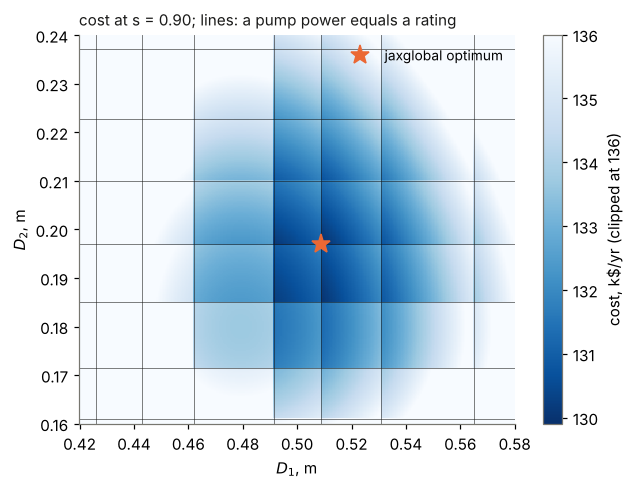

In [10]:
d1, d2 = np.linspace(0.42, 0.58, 321), np.linspace(0.16, 0.24, 321)
A, B = np.meshgrid(d1, d2)
X = np.c_[np.full(A.size, xj[0]), A.ravel(), B.ravel()]
C = np.asarray(cost_v(jnp.asarray(X))).reshape(A.shape)
fig, ax = plt.subplots(figsize=(6.4, 4.6))
pc = ax.pcolormesh(A, B, C / 1000, cmap="Blues_r", vmin=fj / 1000, vmax=136, shading="auto")
fig.colorbar(pc, ax=ax, label="cost, k\\$/yr (clipped at 136)")
for i, dd in ((0, d1), (1, d2)):  # rating boundaries: diameter at which W_i equals a rating
    X1 = np.tile(xj, (dd.size, 1))
    X1[:, 1 + i] = dd
    Wd = np.asarray(power_v(jnp.asarray(X1)))[:, i] / 1000  # decreasing in the diameter
    for k in KW[(KW > Wd.min()) & (KW < Wd.max())]:
        (ax.axvline if i == 0 else ax.axhline)(np.interp(k, Wd[::-1], dd[::-1]), color=INK, lw=0.6, alpha=0.6)
ax.plot(xj[1], xj[2], "*", color=ORANGE, ms=13, label="jaxglobal optimum")
ax.set_xlabel("$D_1$, m")
ax.set_ylabel("$D_2$, m")
ax.set_title(f"cost at s = {xj[0]:.2f}; lines: a pump power equals a rating", loc="left", fontsize=10, color=INK)
ax.grid(False)
ax.legend(frameon=False, fontsize=9, loc="upper right")
plt.show()

## Scaling with the number of switches

Real price lists are often longer once options are included (frame size, enclosure, efficiency class, drive, installed cost). To
see the trend, the same model is solved with price lists of 26, 104, 416 and 1664 ratings, geometrically spaced over the same
0.37 to 315 kW range; the 26-rating case is the IEC list. The continuous model is unchanged; only the number of switches grows.

These runs take up to 600 s each, so they are read from a file produced by

```
cd benchmarks
python flagship.py --classes logic --solvers jaxglobal,scip --time-limit 600 --out results/many_switches.csv \
    --only motor_lines_26,motor_lines_104,motor_lines_416,motor_lines_1664,water_main_26,water_main_104,water_main_416,water_main_1664
```

The jaxglobal times include JIT compilation (cold cache). SCIP is called through `pyscipopt` if the `scip` binary is not installed.

In [11]:
res = pd.read_csv("../benchmarks/results/many_switches.csv")
res["model"] = res["name"].str.rsplit("_", n=1).str[0]
res["K"] = res["name"].str.rsplit("_", n=1).str[1].astype(int)
res["rel_gap"] = (res["primal"] - res["dual"]) / res["primal"].abs()
cols = ["status", "verdict", "time", "rel_gap", "nodes"]
res[res.model == "motor_lines"].pivot_table(index="K", columns="solver", values=cols, aggfunc="first")[cols].round(4)

status               verdict                time            \
solver jaxglobal        scip jaxglobal      scip jaxglobal      scip   
K                                                                      
26       optimal     optimal   correct   correct   76.0950   25.9808   
104      optimal     optimal   correct   correct   74.1275   28.7356   
416      optimal  time_limit   correct  unsolved   78.0758  600.0002   
1664     optimal  time_limit   correct  unsolved  100.1838  600.0008   

         rel_gap              nodes          
solver jaxglobal     scip jaxglobal    scip  
K                                            
26        0.0001   0.0001       413   13681  
104       0.0001   0.0000       955   11509  
416       0.0001   0.0989      3517  274931  
1664      0.0001  20.8716      6181    8439

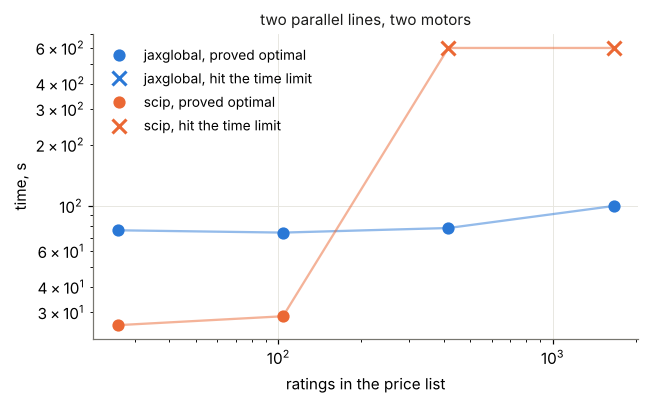

In [12]:
def plot(model, title):
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    for solver, col in (("jaxglobal", BLUE), ("scip", ORANGE)):
        d = res[(res.model == model) & (res.solver == solver)].sort_values("K")
        done = d.status == "optimal"
        ax.loglog(d.K, d.time, "-", color=col, lw=1.5, alpha=0.5)
        ax.loglog(d.K[done], d.time[done], "o", color=col, ms=7, label=f"{solver}, proved optimal")
        ax.loglog(d.K[~done], d.time[~done], "x", color=col, ms=9, mew=2, label=f"{solver}, hit the time limit")
    ax.set_xlabel("ratings in the price list")
    ax.set_ylabel("time, s")
    ax.set_title(title, fontsize=10, color=INK)
    ax.legend(frameon=False, fontsize=9)
    plt.show()


plot("motor_lines", "two parallel lines, two motors")

jaxglobal's time hardly changes with the length of the list, because its search is over the same three variables. Its node count
does grow (from 413 boxes at 26 ratings to 6181 at 1664), because more boundary surfaces cross the region near the optimum, but
the time grows far less than the node count (76 s to 100 s). With the binary formulation, the search also
runs over the ratings: SCIP is faster on the short lists and does not close the gap within 600 s on the long ones (see the gap
column above).

## A counterexample: one pump on a branched main

The advantage depends on the structure of the model, not just on the number of switches. `water_main_<K>` in
`jaxglobal/applications/logic.py` uses the same price lists for the single pump of a branched water main: a 1500 m trunk feeds two
users, 0.12 m3/s lifted 15 m through 1000 m of pipe and 0.08 m3/s lifted 5 m through 2500 m. The decision variables are the three
diameters. The pump serves the harder branch, so the head is a `jnp.maximum` of the two; in Pyomo that is two inequalities on a head
variable, which is exact only because the cost increases with the head.

With $j = 0$ the trunk ($Q_0 = 0.2$ m3/s, $L_0 = 1500$ m) and $j = 1, 2$ the branches, each friction head is
$h_j = f_j \frac{L_j}{D_j}\frac{v_j^2}{2g}$ with the same Swamee-Jain $f_j$ as above, and

$$ H = h_0 + \max\big(h_1 + z_1,\ h_2 + z_2\big),\qquad W = \frac{\rho g Q_0 H}{\eta}, $$

with $z_1 = 15$ m and $z_2 = 5$ m. The cost is one motor from the same staircase, $e\,W$ and the pipe cost of three segments. In
Pyomo, $H$ is a variable with $H \ge h_0 + h_1 + z_1$ and $H \ge h_0 + h_2 + z_2$, plus one set of $K$ rating binaries.

In [13]:
res[res.model == "water_main"].pivot_table(index="K", columns="solver", values=cols, aggfunc="first")[cols].round(4)

status            verdict               time           rel_gap  \
solver jaxglobal     scip jaxglobal     scip jaxglobal    scip jaxglobal   
K                                                                          
26       optimal  optimal   correct  correct   72.2301  0.4846    0.0001   
104      optimal  optimal   correct  correct   94.5429  0.4731    0.0001   
416      optimal  optimal   correct  correct  100.3400  0.7383    0.0001   
1664     optimal  optimal   correct  correct  102.4501  1.5725    0.0001   

                   nodes       
solver    scip jaxglobal scip  
K                              
26      0.0001        77    3  
104     0.0000       369    3  
416     0.0001       635    1  
1664    0.0001      1171    1

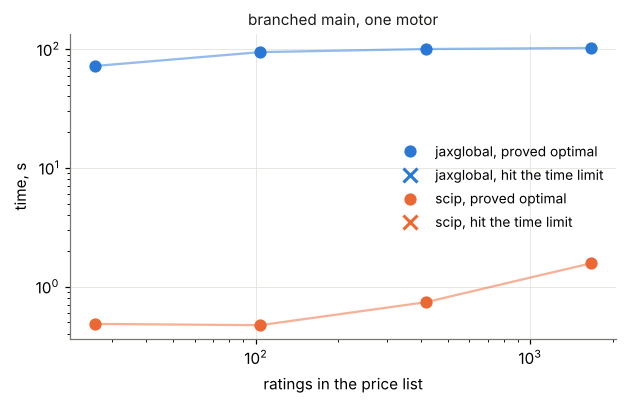

In [14]:
plot("water_main", "branched main, one motor")

Here SCIP stays fast for every list length, and it needs only one to three nodes. The static lift puts a floor under the pump
power and the largest motor puts a ceiling on it, so SCIP's presolve can fix most of the rating binaries before the search starts
(in the runs for this notebook, 1664 ratings left 147 binaries). jaxglobal's time is again roughly flat, but now it is the slower
solver throughout.

The contrast with the two-line model is visible from the variable bounds alone. Each pump power is monotone in the diameters (and,
for the two lines, in the split), so its range over the box comes from the corners. A rating can be the one bought only if it is
the smallest that covers some power in that range; every other binary can be fixed to 0 without search.

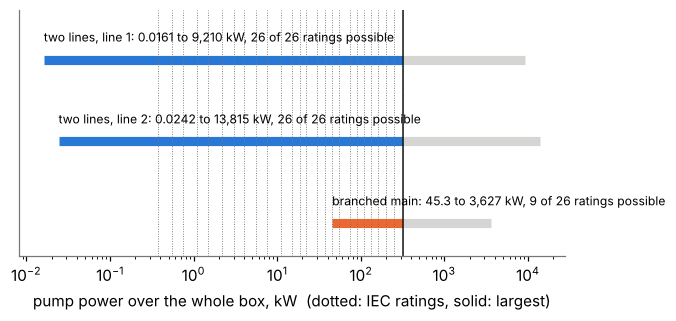

,"two lines, line 1","two lines, line 2",branched main
ratings in the list,,,
26,26,26,9
104,104,104,30
416,416,416,120
1664,1664,1664,479


In [15]:
def power_range_lines(i):  # kW; line i carries the most flow and has the narrowest pipe at one corner, the opposite at another
    W = lambda x: float(power(jnp.asarray(x))[i]) / 1000
    return (W([0.1, 0.6, 0.6]), W([0.9, 0.15, 0.15])) if i == 0 else (W([0.9, 0.6, 0.6]), W([0.1, 0.15, 0.15]))


ranges = {"two lines, line 1": power_range_lines(0), "two lines, line 2": power_range_lines(1),
          "branched main": tuple(float(logic._water_power(jnp.full(3, d))) / 1000 for d in (0.6, 0.15))}  # fmt: skip


def possible(kw, lo, hi):  # ratings that are the smallest cover of some load in [lo, min(hi, largest rating)]
    return np.searchsorted(kw, min(hi, kw[-1])) - np.searchsorted(kw, lo) + 1


fig, ax = plt.subplots(figsize=(6.4, 2.9))
for j, (name, (a, b)) in enumerate(ranges.items()):
    y = 2 - j
    ax.plot([a, min(b, KW[-1])], [y, y], color=BLUE if j < 2 else ORANGE, lw=6, solid_capstyle="butt")
    ax.plot([KW[-1], b], [y, y], color=MUTED, lw=6, alpha=0.3, solid_capstyle="butt")  # beyond the largest motor: infeasible
    ax.text(a, y + 0.22, f"{name}: {a:.3g} to {b:,.0f} kW, {possible(KW, a, b)} of {len(KW)} ratings possible", fontsize=8)
for k in KW:
    ax.axvline(k, color=MUTED, lw=0.6, ls=":")
ax.axvline(KW[-1], color=INK, lw=1)
ax.set_xscale("log")
ax.set_yticks([])
ax.set_ylim(-0.4, 2.6)
ax.grid(False)
ax.set_xlabel("pump power over the whole box, kW  (dotted: IEC ratings, solid: largest)")
plt.show()
pd.DataFrame({name: [possible(logic._water_ratings(K), *r) for K in (26, 104, 416, 1664)] for name, r in ranges.items()},
             index=pd.Index([26, 104, 416, 1664], name="ratings in the list"))  # fmt: skip

In the two-line model either line can carry as little as 10% of the flow through the widest pipe, or 90% through the narrowest,
so its power can be anywhere from tens of watts to far beyond the largest motor and no rating can be ruled out. In the branched main
the 15 m lift alone needs more than 40 kW, so the small ratings drop out before anything is solved. The box bounds alone leave the
share in the table; SCIP's presolve, which also propagates the constraints, goes further (147 of 1664). With
almost every binary fixed, what is left is a smooth problem in three diameters, which SCIP solves at or next to the root.

## Where jaxglobal fails: switches inside a time loop

The opposite case is a switch whose result feeds the next switch. A tank refilled by an on/off pump with a hysteresis controller,
`on = where(h < lo * V, 1, where(h > hi * V, 0, on))` inside a loop over hours, is natural code, and the decision variables (tank
volume $V \in [50, 500]$ m3, pump capacity $Q_p \in [40, 150]$ m3/h, set points $\ell \in [0.05, 0.9]$ and $u \in [0.1, 0.95]$ as
fractions of $V$, with $u \ge \ell + 0.05$) are few. Starting from $h_0 = 0.5V$ and $\text{on}_{-1} = 0$, each hour $t$ is

$$ \text{on}_t = \begin{cases} 1 & h_t < \ell V \\ 0 & h_t > u V \\ \text{on}_{t-1} & \text{otherwise}\end{cases},\qquad
   \tilde h = h_t + \text{on}_t Q_p - d_t,\qquad \text{short}_t = \max(-\tilde h, 0),\qquad
   h_{t+1} = \min(\max(\tilde h, 0), V), $$

with demand $d_t = 40 + 25\sin^2\!\big(2\pi(t-8)/24\big) + 10\,[t \bmod 7 = 3]$ m3/h. Energy costs 0.4 kWh/m3 at 0.25
\$/kWh from 8 to 20 h and 0.08 \$/kWh otherwise, unmet demand costs 5 \$/m3, and the 12-hour operating cost is scaled to a year
and added to the capital cost $2V^{0.6} + 3Q_p^{0.7}$ (k\$/yr).

The controller state after a few steps depends on every earlier branch, and interval bounds on it soon cover both branches
everywhere. In runs made while writing this notebook (12 hourly steps, 4 variables), jaxglobal's best point after 120 s cost
98.60 against an optimum of 96.79, and its lower bound never rose above the capital cost of the smallest tank and pump (60.59), a
38% gap. SCIP, on the model from `jaxglobal.export` with a binary for each comparison, proved 96.79 in 2.5 s. The SCIP half is
cheap enough to repeat here:

In [16]:
from jaxglobal import export

T = 12
hrs = np.arange(T)
DEM = 40 + 25 * np.sin(2 * np.pi * (hrs - 8) / 24) ** 2 + 10 * (hrs % 7 == 3)  # m3/h
TOU = np.where((hrs >= 8) & (hrs < 20), 0.25, 0.08)  # $/kWh


def tank(x, trace=False):  # k$/yr
    V, Qp, lo_f, hi_f = x[0], x[1], x[2], x[3]
    h, on, run, hist = 0.5 * V, 0.0, 0.0, []
    for t in range(T):
        on = jnp.where(h < lo_f * V, 1.0, jnp.where(h > hi_f * V, 0.0, on))  # hysteresis controller
        h = h + on * Qp - DEM[t]
        short = jnp.maximum(-h, 0.0)
        h = jnp.clip(h, 0.0, V)
        run = run + on * Qp * 0.4 * TOU[t] + 5.0 * short  # $ per 12 h: energy at 0.4 kWh/m3, shortage at 5 $/m3
        hist.append((on, h, short))
    total = run * (365 * 24 / T) / 1000 + 2.0 * V**0.6 + 3.0 * Qp**0.7
    return (total, hist) if trace else total


def tank_ineq(x):  # g(x) <= 0: the off set point is at least 5% of V above the on set point
    return jnp.array([x[2] + 0.05 - x[3]])


TLO, THI = np.array([50.0, 40.0, 0.05, 0.1]), np.array([500.0, 150.0, 0.9, 0.95])
ms = export.to_scip(tank, TLO, THI, ineq=tank_ineq)
ms.hideOutput()
ms.setParam("limits/time", 60)
ms.setParam("limits/gap", 1e-4)
ms.optimize()
xt = np.asarray(export.solution(ms))
print(f"SCIP: {ms.getStatus()}, objective {ms.getObjVal():.4f}, bound {ms.getDualbound():.4f}, "
      f"{ms.getNBinVars()} binaries, {ms.getSolvingTime():.1f} s")  # fmt: skip
print(f"x = {np.round(xt, 5)}; the code at x gives {float(tank(jnp.asarray(xt))):.4f}")

SCIP: optimal, objective 96.7919, bound 96.7919, 23 binaries, 3.1 s
x = [50.      58.85016  0.66121  0.87931]; the code at x gives 96.7919


capital 72.91 k$/yr, operation 23.89 k$/yr, unmet demand 0 m3 in 12 h, pump on 11 of 12 hours


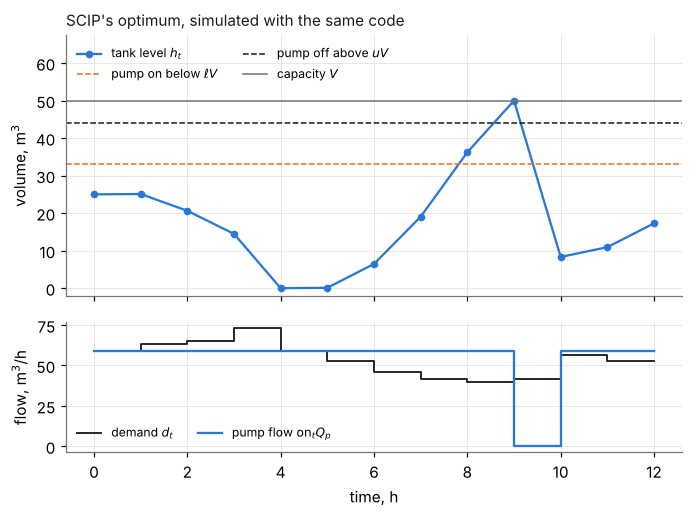

In [17]:
total, hist = tank(xt, trace=True)
on = np.array([float(o) for o, _, _ in hist])
lev = np.r_[0.5 * xt[0], [float(h) for _, h, _ in hist]]
short = sum(float(s) for _, _, s in hist)
cap = 2.0 * xt[0] ** 0.6 + 3.0 * xt[1] ** 0.7
print(f"capital {cap:.2f} k$/yr, operation {float(total) - cap:.2f} k$/yr, unmet demand {short:.3g} m3 in 12 h, "
      f"pump on {int(on.sum())} of {T} hours")  # fmt: skip
t = np.arange(T + 1)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(6.4, 4.8), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
a1.plot(t, lev, "o-", color=BLUE, lw=1.5, ms=4, label="tank level $h_t$")
a1.axhline(xt[2] * xt[0], color=ORANGE, lw=1, ls="--", label=r"pump on below $\ell V$")
a1.axhline(xt[3] * xt[0], color=INK, lw=1, ls="--", label="pump off above $uV$")
a1.axhline(xt[0], color=MUTED, lw=1, label="capacity $V$")
a1.set_ylabel("volume, m$^3$")
a1.set_title("SCIP's optimum, simulated with the same code", loc="left", fontsize=10, color=INK)
a1.legend(frameon=False, fontsize=8, ncol=2, loc="upper left")
a1.set_ylim(-2, 1.35 * xt[0])
a2.step(t, np.r_[DEM, DEM[-1]], where="post", color=INK, lw=1.2, label="demand $d_t$")
a2.step(t, np.r_[on, on[-1]] * xt[1], where="post", color=BLUE, lw=1.5, label=r"pump flow $\mathrm{on}_t Q_p$")
a2.set_ylabel("flow, m$^3$/h")
a2.set_xlabel("time, h")
a2.legend(frameon=False, fontsize=8, ncol=2, loc="lower left")
fig.tight_layout()
plt.show()

The optimum is again on a boundary of the switches: the smallest tank, a pump just large enough that the level touches zero
without a shortage, and set points placed so that the pump is switched off for one hour of the expensive daytime period, when the
tank is full. Each such boundary is a condition on the whole history of the level, which is why the binaries in SCIP's model are
chained through time and why interval bounds on the level lose track of which branch was taken.

## Summary

* **Representation.** A price list is one line of `jnp.where`. In Pyomo it is a binary per rating plus two constraints, and a
  `max` needs an argument about monotonicity before it can be written as inequalities.
* **When native switches pay off:** few continuous variables, and many switches that each depend on a quantity the solver cannot
  bound tightly in presolve. Then jaxglobal's time stays roughly flat while the binary formulation grows (two parallel lines).
* **When they do not:** if presolve can fix most of the binaries (branched main), or if switches are chained through time (the
  controller), the equation-based solver is faster, in the second case by a wide margin.
* **Ties.** The optimum sits exactly on a rating boundary, where the cost jumps. Writing the test as `W > rating` means the boundary
  point gets the cheaper motor, so the minimum is attained. Equation-based solvers satisfy $W \le P_k$ only up to their feasibility
  tolerance, so evaluate the code at their returned point before trusting the cost.
* **Bugs found while building this comparison.** At near-ties, the compiled gradient of `jnp.maximum` inside the bounding loop was
  not a subgradient, which let jaxglobal report a wrong optimum on the 26-rating two-line model (fixed in PR #76). The SCIP export
  padded exact 0/1 intervals, so big-M constants of about 1e-9 let SCIP's presolve cut off valid points of the controller model
  (PR #77).